# Bernoulli and Binomial Models for Binary Outcomes in Machine Learning

A simple Python experiment modeling correct and incorrect classifier predictions.

## 1. Experiment Setup

This experiment models the predictions of a binary classifier.

Each prediction has two possible outcomes:

- `1`: correct prediction
- `0`: incorrect prediction

The probability of a correct prediction is set to `p = 0.80`, and the experiment begins with `n = 10` predictions. A fixed random seed is used to make the simulated results reproducible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

np.random.seed(42)

p = 0.80   # probability of a correct prediction
n = 10     # number of predictions

print(f"Probability of a correct prediction: {p:.0%}")
print(f"Number of predictions: {n}")

Probability of a correct prediction: 80%
Number of predictions: 10


## 2. Simulating Individual Bernoulli Trials

Each classifier prediction is modeled as an independent Bernoulli trial.

Although NumPy's `binomial` function is used, setting `n = 1` produces a Bernoulli outcome for each trial. The simulation generates `n` individual predictions and counts the observed successes and failures.

In [2]:
bernoulli_trials = np.random.binomial(
    n=1,
    p=p,
    size=n
)

observed_successes = int(bernoulli_trials.sum())
observed_failures = n - observed_successes

print("Individual Prediction Outcomes:")
print(bernoulli_trials)

print(f"Observed correct predictions: {observed_successes}")
print(f"Observed incorrect predictions: {observed_failures}")


Individual Prediction Outcomes:
[1 0 1 1 1 1 1 0 1 1]
Observed correct predictions: 8
Observed incorrect predictions: 2


## 3. Exact Binomial Probability

The Binomial model counts the number of successes across repeated Bernoulli trials.

In this section, the target is exactly 8 correct predictions out of 10. The Binomial probability formula is used to calculate this probability together with the expected value, variance, and standard deviation.

In [3]:
target_successes = 8

probability_target = (
    math.comb(n, target_successes)
    * (p ** target_successes)
    * ((1 - p) ** (n - target_successes))
)

expected_value = n * p
variance = n * p * (1 - p)
standard_deviation = math.sqrt(variance)

print(
    f"P(X = {target_successes}) = "
    f"{probability_target:.4f}"
)

print(
    f"Probability of exactly {target_successes} correct predictions: "
    f"{probability_target:.2%}"
)

print(f"Expected number of correct predictions: {expected_value:.2f}")
print(f"Variance: {variance:.2f}")
print(f"Standard deviation: {standard_deviation:.2f}")

P(X = 8) = 0.3020
Probability of exactly 8 correct predictions: 30.20%
Expected number of correct predictions: 8.00
Variance: 1.60
Standard deviation: 1.26


## 4. Full Binomial Probability Distribution

Instead of calculating only one outcome, this section computes the probability of every possible number of correct predictions from 0 to 10.

The bar chart visualizes the complete theoretical Binomial distribution. Since `p = 0.80`, most of the probability mass is concentrated around 8 correct predictions.

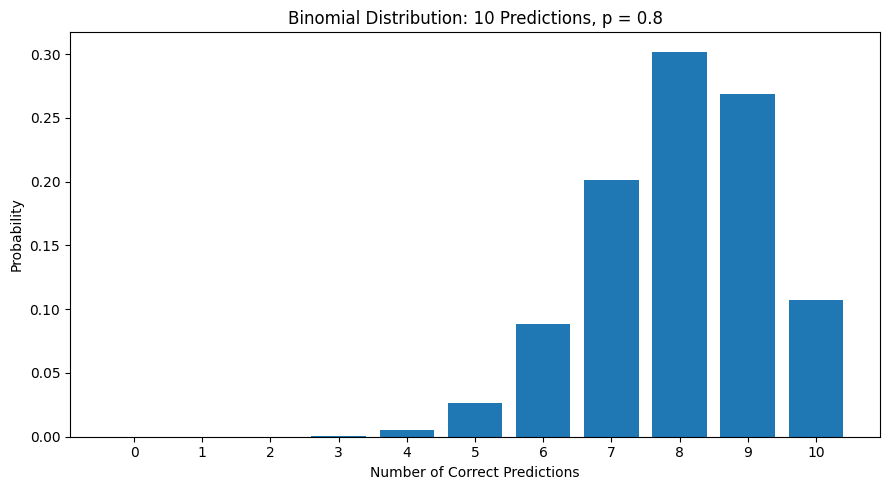

In [4]:
success_counts = np.arange(0, n + 1)

probabilities = [
    math.comb(n, success_count)
    * (p ** success_count)
    * ((1 - p) ** (n - success_count))
    for success_count in success_counts
]

plt.figure(figsize=(9, 5))
plt.bar(success_counts, probabilities)

plt.xlabel("Number of Correct Predictions")
plt.ylabel("Probability")
plt.title(f"Binomial Distribution: {n} Predictions, p = {p}")
plt.xticks(success_counts)

plt.tight_layout()
plt.show()

## 5. Monte Carlo Simulation: Theory vs. Experiment

The 10-prediction experiment is repeated 1,000 times.

Each value in the simulation represents the total number of correct predictions in one 10-prediction experiment. The empirical average is then compared with the theoretical expected value, `n × p`.

As the number of repeated experiments increases, the empirical average is expected to approach the theoretical value.

In [5]:
number_of_experiments = 1000

simulations = np.random.binomial(
    n=n,
    p=p,
    size=number_of_experiments
)

empirical_average = simulations.mean()
theoretical_average = n * p

print(
    f"Average correct predictions across "
    f"{number_of_experiments} experiments: "
    f"{empirical_average:.2f}"
)

print(
    f"Theoretical expected value: "
    f"{theoretical_average:.2f}"
)

Average correct predictions across 1000 experiments: 8.05
Theoretical expected value: 8.00


## 6. Baseline Findings

- A single classifier prediction can be modeled as a Bernoulli trial.
- The total number of correct predictions across repeated trials follows a Binomial distribution.
- With `n = 10` and `p = 0.80`, the expected number of correct predictions is exactly 8.
- This does not mean that every experiment produces exactly 8 successes.
- In 1,000 simulated experiments, the empirical mean was close to the theoretical expected value.

## 7. Effect of Changing the Success Probability

This experiment keeps the number of predictions fixed at `n = 10` and compares different success probabilities.

The values `p = 0.50`, `0.70`, `0.80`, and `0.90` represent classifiers with different probabilities of producing a correct prediction.

The goal is to observe how the Binomial distribution changes as the probability of success increases.

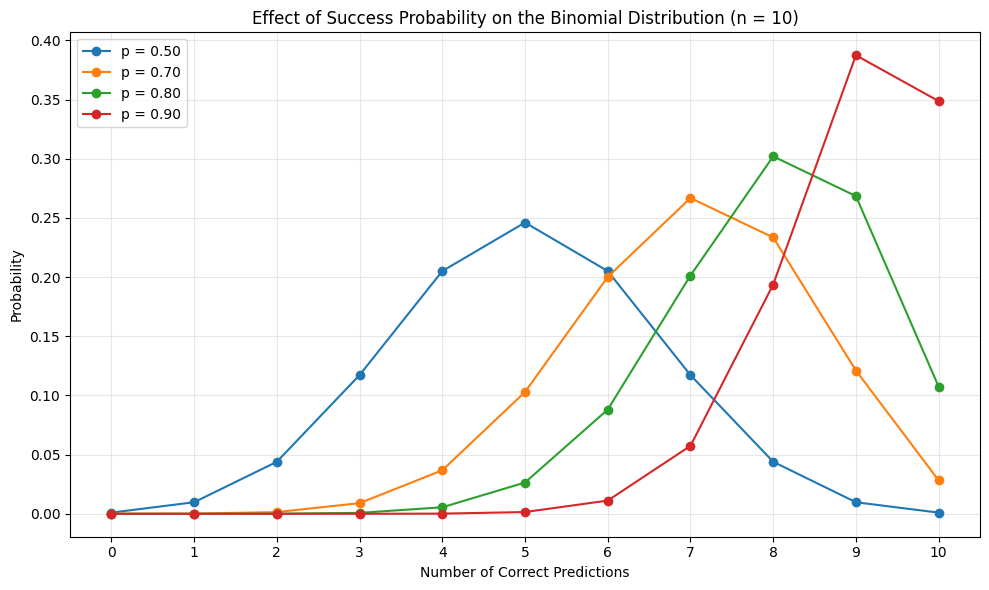

In [6]:
p_values = [0.50, 0.70, 0.80, 0.90]
success_counts = np.arange(0, n + 1)

plt.figure(figsize=(10, 6))

for probability in p_values:
    distribution = [
        math.comb(n, success_count)
        * (probability ** success_count)
        * ((1 - probability) ** (n - success_count))
        for success_count in success_counts
    ]

    plt.plot(
        success_counts,
        distribution,
        marker="o",
        label=f"p = {probability:.2f}"
    )

plt.xlabel("Number of Correct Predictions")
plt.ylabel("Probability")
plt.title(f"Effect of Success Probability on the Binomial Distribution (n = {n})")
plt.xticks(success_counts)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Key Observation

As the probability of success increases, the Binomial distribution shifts toward larger numbers of correct predictions.

For `n = 10`, the distributions are centered around their expected values:

- `p = 0.50` → 5 expected correct predictions
- `p = 0.70` → 7 expected correct predictions
- `p = 0.80` → 8 expected correct predictions
- `p = 0.90` → 9 expected correct predictions

The `p = 0.50` distribution is more spread out, while higher success probabilities concentrate more probability near the upper end of the possible outcomes.

## 8. Effect of Increasing the Number of Predictions

This experiment keeps the success probability fixed at `p = 0.80` and examines how the number of predictions affects the variability of the observed accuracy.

The expected accuracy remains equal to `p`, regardless of the sample size. However, the standard deviation of the observed success rate is:

$$
\sqrt{\frac{p(1-p)}{n}}
$$

As `n` increases, the observed accuracy is expected to become more stable around the theoretical probability.

n =  10 | Expected accuracy = 80% | Accuracy standard deviation = 0.1265
n =  20 | Expected accuracy = 80% | Accuracy standard deviation = 0.0894
n =  50 | Expected accuracy = 80% | Accuracy standard deviation = 0.0566
n = 100 | Expected accuracy = 80% | Accuracy standard deviation = 0.0400
n = 200 | Expected accuracy = 80% | Accuracy standard deviation = 0.0283
n = 500 | Expected accuracy = 80% | Accuracy standard deviation = 0.0179


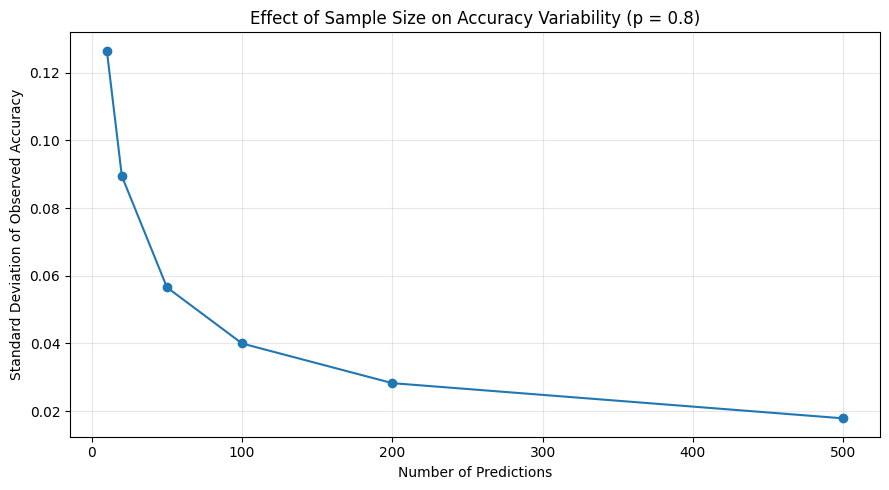

In [7]:
sample_sizes = np.array([10, 20, 50, 100, 200, 500])

accuracy_standard_deviations = np.sqrt(
    p * (1 - p) / sample_sizes
)

for sample_size, accuracy_std in zip(
    sample_sizes,
    accuracy_standard_deviations
):
    print(
        f"n = {sample_size:>3} | "
        f"Expected accuracy = {p:.0%} | "
        f"Accuracy standard deviation = {accuracy_std:.4f}"
    )

plt.figure(figsize=(9, 5))

plt.plot(
    sample_sizes,
    accuracy_standard_deviations,
    marker="o"
)

plt.xlabel("Number of Predictions")
plt.ylabel("Standard Deviation of Observed Accuracy")
plt.title(
    f"Effect of Sample Size on Accuracy Variability "
    f"(p = {p})"
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Key Observation

Increasing the sample size does not change the underlying success probability, which remains fixed at `p = 0.80`.

However, it reduces the variability of the observed accuracy:

- With `n = 10`, the standard deviation is approximately `0.1265`.
- With `n = 100`, the standard deviation decreases to `0.0400`.
- With `n = 500`, it decreases further to approximately `0.0179`.

Therefore, accuracy estimates obtained from larger samples are more stable and more likely to remain close to the true success probability.

## 9. Convergence of the Empirical Mean

This experiment examines how the empirical average changes as the number of repeated experiments increases.

Each experiment contains `n = 10` predictions with a success probability of `p = 0.80`. Therefore, the theoretical expected number of correct predictions is:

$$
E[X] = n \times p = 8
$$

A running average is calculated across 10,000 repeated experiments. As more experiments are included, the empirical average is expected to fluctuate less and remain closer to the theoretical expected value.

After    10 experiments | Empirical average = 7.6000 | Theoretical average = 8.00
After   100 experiments | Empirical average = 7.7800 | Theoretical average = 8.00
After  1000 experiments | Empirical average = 7.9810 | Theoretical average = 8.00
After 10000 experiments | Empirical average = 8.0250 | Theoretical average = 8.00


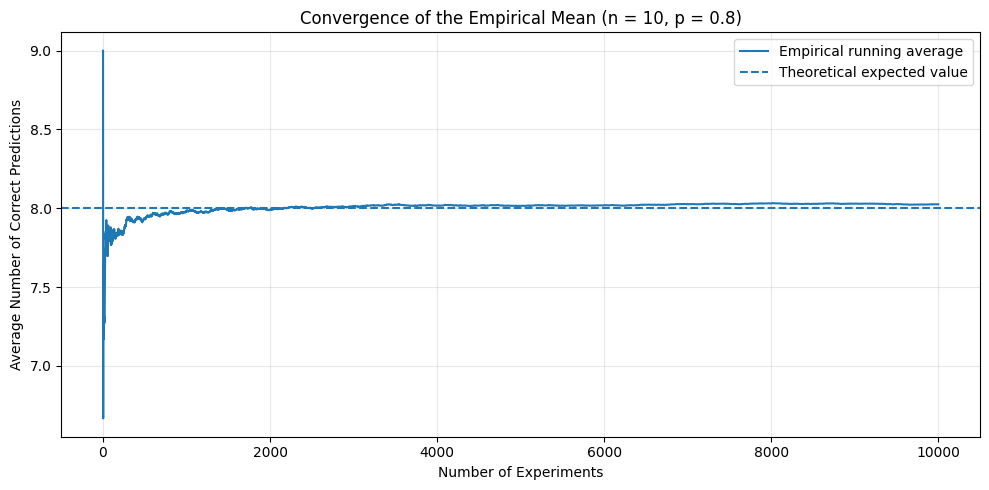

In [8]:
maximum_experiments = 10_000

simulation_results = np.random.binomial(
    n=n,
    p=p,
    size=maximum_experiments
)

experiment_counts = np.arange(1, maximum_experiments + 1)

running_averages = (
    np.cumsum(simulation_results)
    / experiment_counts
)

theoretical_average = n * p
checkpoints = [10, 100, 1_000, 10_000]

for checkpoint in checkpoints:
    print(
        f"After {checkpoint:>5} experiments | "
        f"Empirical average = "
        f"{running_averages[checkpoint - 1]:.4f} | "
        f"Theoretical average = {theoretical_average:.2f}"
    )

plt.figure(figsize=(10, 5))

plt.plot(
    experiment_counts,
    running_averages,
    label="Empirical running average"
)

plt.axhline(
    y=theoretical_average,
    linestyle="--",
    label="Theoretical expected value"
)

plt.xlabel("Number of Experiments")
plt.ylabel("Average Number of Correct Predictions")
plt.title(
    "Convergence of the Empirical Mean "
    f"(n = {n}, p = {p})"
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Key Observation

With only a small number of repeated experiments, the empirical average can noticeably differ from the theoretical expected value.

In this simulation:

- After 10 experiments, the empirical average was `7.6000`.
- After 100 experiments, it was `7.7800`.
- After 1,000 experiments, it reached `7.9810`.
- After 10,000 experiments, it was `8.0250`.

The theoretical expected value is:

$$
E[X] = n \times p = 10 \times 0.80 = 8
$$

The running average does not approach the expected value in a perfectly smooth or monotonic way. However, as the number of experiments increases, random fluctuations become less influential and the empirical mean stabilizes near the theoretical value.

## 10. Final Findings

This notebook explored Bernoulli and Binomial models through the example of binary classifier predictions.

The main findings are:

- A single classifier prediction can be modeled as a Bernoulli trial with two possible outcomes: correct or incorrect.
- The total number of correct predictions across repeated independent trials follows a Binomial distribution.
- With `n = 10` and `p = 0.80`, the expected number of correct predictions is 8, but individual experiments may produce different results.
- The probability of exactly 8 correct predictions is approximately `30.20%`.
- Increasing the success probability shifts the Binomial distribution toward larger numbers of successes.
- Increasing the number of predictions reduces the variability of the observed accuracy.
- Repeating the experiment many times causes the empirical average to stabilize near the theoretical expected value.

These experiments demonstrate the difference between the probability of an individual outcome, the distribution of repeated outcomes, and the long-run behavior of repeated experiments.

### Model Assumptions

The basic Binomial model assumes that:

- each trial has only two possible outcomes;
- trials are independent;
- the probability of success remains constant;
- the number of trials is fixed.

In real machine learning systems, these assumptions should be evaluated carefully because prediction outcomes may not always be independent or identically distributed.